# Nicheformer Benchmarking

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 04.12.2024
- Date of Last Modification: 02.04.2026 (by Sebastian Birk; sb75@sanger.ac.uk)

- Run this notebook in the nicheformer conda environment, installable from ```../../envs/nicheformer.yaml```.
- Clone Nicheformer from GitHub into ```<root>/analysis/benchmarking```: ```git clone https://github.com/theislab/nicheformer```.
- Download the pretrained model weights from https://data.mendeley.com/preview/87gm9hrgm8?a=d95a6dde-e054-4245-a7eb-0522d6ea7dff as described at https://github.com/theislab/nicheformer/blob/main/README.md and put them into the ```./nicheformer/data``` directory.
- For zero shot inference, this notebooks follows the notebook from https://github.com/theislab/nicheformer/blob/main/notebooks/experiments/get_embeddings.ipynb

## 1. Setup

### 1.1 Load Libraries 

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../../utils")
sys.path.append("../benchmarking/nicheformer/src")

In [75]:
# Execute above cells twice
import os
import warnings
from tqdm import tqdm
from typing import Optional, Dict, Any

import anndata as ad
import matplotlib as mpl
import numpy as np
import pytorch_lightning as pl
import scanpy as sc
import sklearn.metrics as skm
import torch
from torch.utils.data import DataLoader
from sklearn.metrics.cluster import adjusted_rand_score, normalized_mutual_info_score

from nicheformer.data import NicheformerDataset
from nicheformer.models import Nicheformer

from analysis_utils import *
from benchmarking_utils import max_overlap_plot

from scib_metrics import ilisi_knn
from scib_metrics.nearest_neighbors import pynndescent

### 1.2 Configure Paths

In [4]:
st_data_folder_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS'
st_data_silver_folder_path = f'{st_data_folder_path}/silver'
artifacts_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts'
benchmarking_artifacts_folder_path = f'{artifacts_folder_path}/benchmarking'
nicheformer_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/analysis/benchmarking/nicheformer'

BASE_PATH = f'{nicheformer_folder_path}/data/model_means'

### 1.3 Define Config

In [37]:
latent_neighborhood_cluster_key = 'predicted_niche'
latent_cell_cluster_key = 'predicted_cell_type'
n_pcs = None
spot_sizes = {'MERFISH': 20,
              'STARmap PLUS': 100}

### 1.4 Run Notebook Setup

In [6]:
warnings.filterwarnings("ignore", category=ResourceWarning)

In [78]:
plt.rcParams['font.size'] = 5
plt.rcParams['text.usetex'] = False
plt.rcParams['svg.fonttype'] = 'none'

In [8]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [9]:
sc.settings.figdir = f'{benchmarking_artifacts_folder_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(3, 2),
    facecolor='white',
    fontsize=7
)

In [10]:
os.makedirs(f'{benchmarking_artifacts_folder_path}/figures', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/results', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/nicheformer', exist_ok=True)

## 2. Zero-shot Niche Identification

### 2.1 mmb0-1b_smb1-1b_1p (MERFISH + STARmap PLUS mouse brain shared panel)

In [11]:
# Define dataset params
dataset_name = 'mmb0-1b_smb1-1b_1p'
batches = ['harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes',
           'harmonised_starmap_plus_mouse_cns_batch15_shared_genes']
niche_key = 'tissue_region'
batch_key = 'batch'
label_keys = [niche_key]
spot_sizes = [100, 20]

OUT_PATH = f'{benchmarking_artifacts_folder_path}/nicheformer/{dataset_name}'
os.makedirs(OUT_PATH, exist_ok=True)

In [13]:
# Define config
config = {
    'data_path': f'{artifacts_folder_path}/nicheformer/{dataset_name}.h5ad',
    'technology_mean_path': f"{BASE_PATH}/merfish_mean_script.npy", #'path/to/technology_mean.npy',  # Path to technology mean file
    'checkpoint_path': f'{nicheformer_folder_path}/data/nicheformer.ckpt',  # Path to model checkpoint
    'output_path': f'{benchmarking_artifacts_folder_path}/nicheformer/{dataset_name}_embedded.h5ad',  # Where to save the result, it is a new h5ad
    'output_dir': '.',  # Directory for any intermediate outputs
    'batch_size': 32,
    'max_seq_len': 1500, 
    'aux_tokens': 30, 
    'chunk_size': 1000, # to prevent OOM
    'num_workers': 4,
    'precision': 32,
    'embedding_layer': -1,  # Which layer to extract embeddings from (-1 for last layer)
    'embedding_name': 'embeddings'  # Name suffix for the embedding key in adata.obsm
}

#### 2.1.1 Prepare Data

In [14]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            print(file)

            if file == 'harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad':
                adata.obs[niche_key] = adata.obs['ccf_region_name']
                adata.obs[batch_key] = file.replace('h5ad', '')
            elif file == 'harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad':
                adata.obs[niche_key] = adata.obs['Sub_molecular_tissue_region']
                adata.obs[batch_key] = file.replace('h5ad', '')                

            # Filter cells without niche labels
            adata = adata[~adata.obs[niche_key].isna()]
            print(adata.obs.columns)
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)

harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad
Index(['donor_id', 'brain_section_label', 'major_brain_region',
       'ccf_region_name', 'cell_type', 'cell_id', 'n_genes',
       'nichecompass_latent_cluster', 'tissue_region', 'batch'],
      dtype='object')
harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad
Index(['Main_molecular_cell_type', 'Sub_molecular_cell_type',
       'Main_molecular_tissue_region', 'Sub_molecular_tissue_region',
       'Molecular_spatial_cell_type', 'dataset', 'cell_type',
       'cell_type_ontology_term_id', 'n_genes', 'cell_id',
       'nichecompass_latent_cluster', 'tissue_region', 'batch'],
      dtype='object')


/nfs/team361/sb75/.venvs/nicheformer/lib/python3.10/site-packages/anndata/_core/merge.py:1434: UserWarning: Only some AnnData objects have `.raw` attribute, not concatenating `.raw` attributes.
  warn(


In [15]:
print(adata.obs[niche_key].value_counts())

TH_2                                                               3192
FT_1                                                               2220
CNU_9                                                              1873
CTX_A_3                                                            1746
TH_4                                                               1618
                                                                   ... 
Ventral anterior-lateral complex of the thalamus                      3
Primary auditory area, layer 1                                        3
CTX_B_9                                                               2
Perirhinal area, layer 6a                                             2
Dorsal part of the lateral geniculate complex, ipsilateral zone       1
Name: tissue_region, Length: 230, dtype: int64


#### 2.1.2 Load Data

In [16]:
model = ad.read_h5ad(f"{BASE_PATH}/model.h5ad")

In [19]:
# Set random seed for reproducibility
pl.seed_everything(42)

# Load mean for normalization
technology_mean = np.load(config['technology_mean_path'])

# format data properly with the model
adata = ad.concat([model, adata], join='outer', axis=0)
# dropping the first observation 
adata = adata[1:].copy()

mask = adata.var_names.isin(model.var_names)
adata = adata[:, mask].copy()

Seed set to 42


As a reference, the metadata tokens are

modality_dict = { 'dissociated': 3, 'spatial': 4,}

specie_dict = { 'human': 5, 'Homo sapiens': 5, 'Mus musculus': 6, 'mouse': 6,}

technology_dict = { "merfish": 7, "MERFISH": 7, "cosmx": 8, "NanoString digital spatial profiling": 8, "visium": 9, "10x 5' v2": 10, "10x 3' v3": 11, "10x 3' v2": 12, "10x 5' v1": 13, "10x 3' v1": 14, "10x 3' transcription profiling": 15, "10x transcription profiling": 15, "10x 5' transcription profiling": 16, "CITE-seq": 17, "Smart-seq v4": 18, }

In [21]:
# Change accordingly
adata.obs['modality'] = 4 # spatial
adata.obs['specie'] = 6 # mouse
adata.obs['technology'] = 7 # merfish

In [22]:
adata.obs['nicheformer_split'] = 'train'

In [24]:
# Create dataset
dataset = NicheformerDataset(
    adata=adata,
    technology_mean=technology_mean,
    split='train',
    max_seq_len=1500,
    aux_tokens=config.get('aux_tokens', 30),
    chunk_size=config.get('chunk_size', 1000),
    metadata_fields={'obs': ['modality', 'specie', 'assay']}
)

# Create dataloader
dataloader = DataLoader(
    dataset,
    batch_size=config['batch_size'],
    shuffle=False,
    num_workers=config.get('num_workers', 4),
    pin_memory=True
)

100%|████████████████████████████████████████████████████████████████| 86/86 [01:04<00:00,  1.33it/s]


#### 2.1.3 Retrieve Embeddings

In [25]:
# Load pre-trained model
model = Nicheformer.load_from_checkpoint(checkpoint_path=config['checkpoint_path'], strict=False)
model.eval()  # Set to evaluation mode

# Configure trainer
trainer = pl.Trainer(
    accelerator='gpu' if torch.cuda.is_available() else 'cpu',
    devices=1,
    default_root_dir=config['output_dir'],
    precision=config.get('precision', 32),
)

💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
HPU available: False, using: 0 HPUs
/nfs/team361/sb75/.venvs/nicheformer/lib/python3.10/site-packages/pytorch_lightning/trainer/connectors/logger_connector/logger_connector.py:76: Starting from v1.9.0, `tensorboardX` has been removed as a dependency of the `pytorch_lightning` package, due to potential conflicts with other packages in the ML ecosystem. For this reason, `logger=True` will use `CSVLogger` as the default logger, unless the `tensorboard` or `tensorboardX` packages are found. Please `pip install lightning[extra]` or one of them to enable TensorBoard support by default


In [26]:
print("Extracting embeddings...")
embeddings = []
device = model.embeddings.weight.device

with torch.no_grad():
    for batch in tqdm(dataloader):
        # Move batch to device
        batch = {k: v.to(device) if isinstance(v, torch.Tensor) else v
                for k, v in batch.items()}

        # Get embeddings from the model
        emb = model.get_embeddings(
            batch=batch,
            layer=config.get('embedding_layer', -1)  # Default to last layer
        )
        embeddings.append(emb.cpu().numpy())

# Concatenate all embeddings
embeddings = np.concatenate(embeddings, axis=0)

Extracting embeddings...


100%|████████████████████████████████████████████████████████████| 2679/2679 [35:56<00:00,  1.24it/s]


In [27]:
# Store embeddings in AnnData object
embedding_key = f"X_niche_{config.get('embedding_name', 'embeddings')}"
adata.obsm[embedding_key] = embeddings

In [28]:
for col in adata.obs.columns:
    if isinstance(adata.obs[col].dtype, pd.CategoricalDtype):
        adata.obs[col] = adata.obs[col].astype(str).astype('category')

adata.obs['cell_id'] = adata.obs['cell_id'].astype(str)
adata.obs.index = adata.obs.index.astype(str)

def fix_arrow_strings(df):
    for col in df.columns:
        if isinstance(df[col].dtype, pd.CategoricalDtype):
            df[col] = df[col].astype(str).astype('category')
        elif isinstance(df[col].array, pd.arrays.ArrowExtensionArray):
            df[col] = df[col].astype(str)
    df.index = df.index.astype(str)
    return df

adata.obs = fix_arrow_strings(adata.obs)
adata.var = fix_arrow_strings(adata.var)

adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/nicheformer/{dataset_name}_embedded.h5ad')

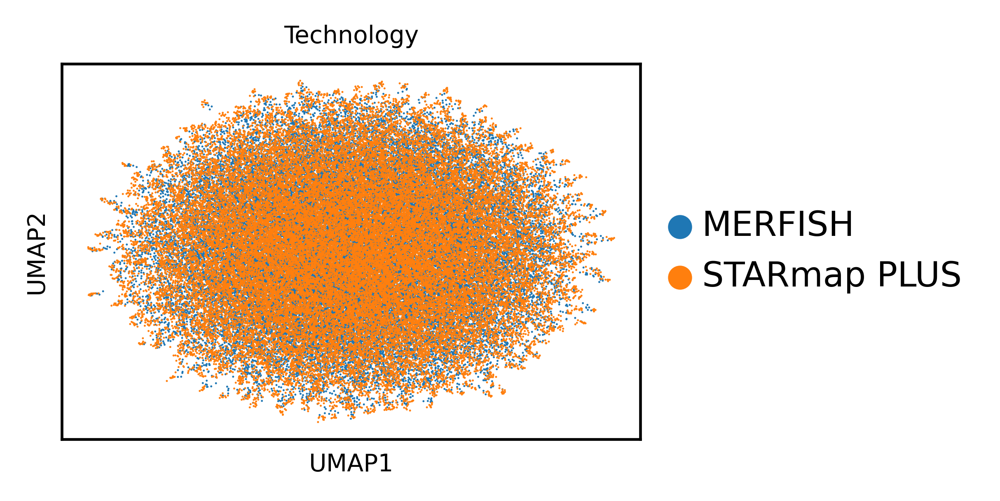

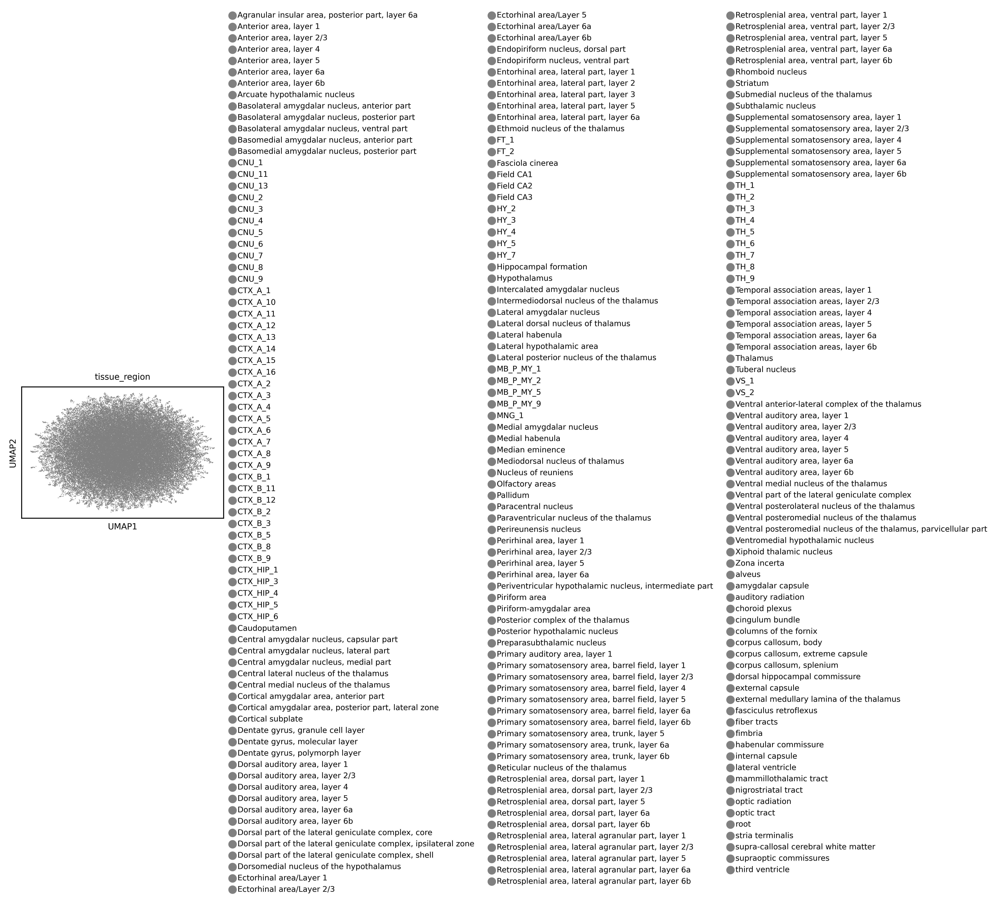

In [80]:
for emb_key in [embedding_key]:
    try:
        rsc.pp.neighbors(adata, n_neighbors=15, use_rep=emb_key,
                         n_pcs=n_pcs, key_added=emb_key)
        rsc.tl.umap(adata, neighbors_key=emb_key)
    except NameError:
        sc.pp.neighbors(adata, n_neighbors=15, use_rep=emb_key,
                        n_pcs=n_pcs, key_added=emb_key)
        sc.tl.umap(adata, neighbors_key=emb_key)

    n_pcs_string = f"_{n_pcs}_pcs" if n_pcs else ""
    categories = adata.obs[batch_key].cat.categories.tolist()
    assert len(categories) == 2, "Expected exactly 2 categories for batch_key"
    rename = dict(zip(sorted(categories), ["MERFISH", "STARmap PLUS"]))
    adata.obs[batch_key] = adata.obs[batch_key].map(rename).astype("category")

    sc.pl.umap(
        adata,
        color=batch_key,
        title="Technology",
        legend_loc="right margin",
        legend_fontsize=10,
        show=False,
    )
    for collection in plt.gca().collections:
        collection.set_rasterized(True)
    plt.savefig(
        f"{benchmarking_artifacts_folder_path}/nicheformer/{dataset_name}_{emb_key}_umap_by_{batch_key}{n_pcs_string}.svg",
        format="svg", bbox_inches="tight"
    )
    plt.show()
    plt.close()

    for label_key in label_keys:
        sc.pl.umap(adata, color=label_key, show=False)
        for collection in plt.gca().collections:
            collection.set_rasterized(True)
        plt.savefig(
            f"{benchmarking_artifacts_folder_path}/nicheformer/{dataset_name}_{emb_key}_umap_by_{label_key}{n_pcs_string}.svg",
            format="svg", bbox_inches="tight"
        )
        plt.show()
        plt.close()

In [30]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/nicheformer/{dataset_name}_embedded.h5ad')

print(f"Embeddings saved to {f'{benchmarking_artifacts_folder_path}/nicheformer/{dataset_name}_embedded.h5ad'} in obsm['{embedding_key}']")

Embeddings saved to /nfs/team361/sb75/nichejepa-reproducibility/artifacts/benchmarking/nicheformer/mmb0-1b_smb1-1b_1p_embedded.h5ad in obsm['X_niche_embeddings']


In [31]:
adata = sc.read_h5ad(f'{benchmarking_artifacts_folder_path}/nicheformer/{dataset_name}_embedded.h5ad')

In [54]:
latent_leiden_resolution = 0.151

In [55]:
# Plot embedding-based clusters
for emb_key in ['X_niche_embeddings']:
    latent_cluster_key = f"{emb_key}_clusters_res_{latent_leiden_resolution}"
    
    try:
        rsc.tl.leiden(adata,
                      neighbors_key=emb_key,
                      key_added=latent_cluster_key,
                      resolution=latent_leiden_resolution,
                      flavor="igraph",
                      n_iterations=2)
    except NameError:
        sc.tl.leiden(adata,
                     neighbors_key=emb_key,
                     key_added=latent_cluster_key,
                     resolution=latent_leiden_resolution,
                     flavor="igraph",
                     n_iterations=2)

In [56]:
adata.obs[latent_cluster_key].value_counts()

0     85481
1        16
2        16
3        16
4        16
5        16
6        16
7        16
8        16
9        16
10       16
12       16
13       16
14       16
11       15
Name: X_niche_embeddings_clusters_res_0.151, dtype: int64

/tmp/ipykernel_2741388/3798748774.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/nfs/team361/sb75/.venvs/nicheformer/lib/python3.10/site-packages/scanpy/plotting/_utils.py:482: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


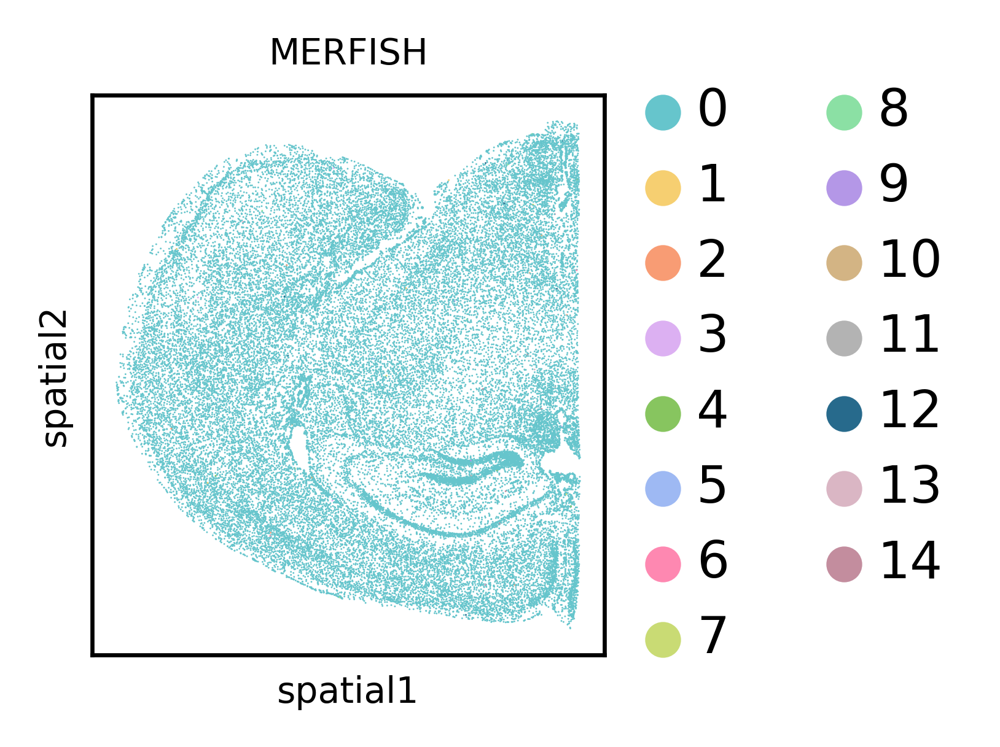

/tmp/ipykernel_2741388/3798748774.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(
/nfs/team361/sb75/.venvs/nicheformer/lib/python3.10/site-packages/scanpy/plotting/_utils.py:482: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


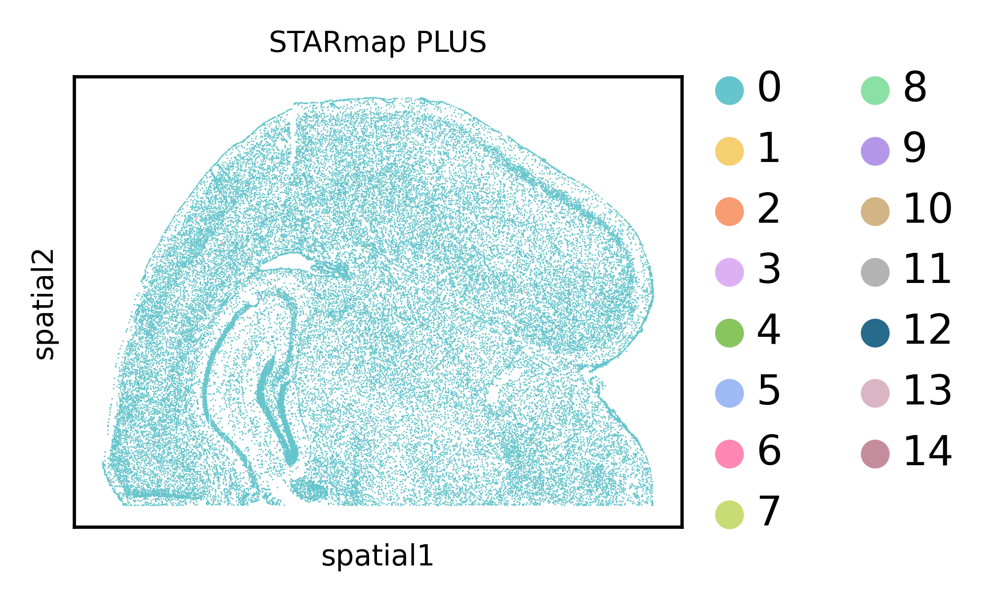

In [79]:
samples = adata.obs[batch_key].unique().tolist()
for sample in samples:
    adata_sample = adata[adata.obs[batch_key] == sample]
    sc.pl.spatial(
        adata_sample,
        color=latent_cluster_key,
        palette=custom_palette,
        spot_size=spot_sizes[sample],
        title=sample,
        legend_loc="right margin",
        legend_fontsize=10,
        show=False,
    )

    fig = plt.gcf()
    for ax in fig.axes:
        for child in ax.get_children():
            if isinstance(child, mpl.image.AxesImage):
                child.set_rasterized(True)
        for collection in ax.collections:
            collection.set_rasterized(True)

    plt.savefig(
        f"{benchmarking_artifacts_folder_path}/nicheformer/tissue_{sample}_by_{latent_cluster_key}.svg",
        format="svg", bbox_inches="tight"
    )
    plt.show()
    plt.close()

In [64]:
# Save updated AnnData
adata.write_h5ad(f'{benchmarking_artifacts_folder_path}/nicheformer/{dataset_name}_embedded_clustered.h5ad')

In [68]:
# Compute NMI with region annotations
mask = adata.obs["Sub_molecular_tissue_region"].notna()
labels_true = adata.obs.loc[mask, "Sub_molecular_tissue_region"]
labels_pred = adata.obs.loc[mask, latent_cluster_key]

nmi = skm.normalized_mutual_info_score(labels_true, labels_pred)
print(f"NMI (Sub_molecular_tissue_region): {nmi:.4f}")

mask = adata.obs["ccf_region_name"].notna()
labels_true = adata.obs.loc[mask, "ccf_region_name"]
labels_pred = adata.obs.loc[mask, latent_cluster_key]

nmi = skm.normalized_mutual_info_score(labels_true, labels_pred)
print(f"NMI (ccf_region_name): {nmi:.4f}")

NMI: 0.0023
NMI (ccf_region_name): 0.0019


In [76]:
# Compute iLISI
batch_key = "batch"
batch = adata.obs[batch_key].values

knn = pynndescent(adata.obsm['X_niche_embeddings'], n_neighbors=90)
score = ilisi_knn(knn, batch)
print(f"iLISI ({'X_niche_embeddings'}): {score:.4f}")

iLISI (X_niche_embeddings): 0.9527


In [83]:
# Compute average cosine similarity to check embeddings are not collapsed
# (this should be < 0.9 otherwise the embeddings might not be useful; this can happen if the gene panel is too small)
for emb_key in ['X_niche_embeddings']:
    X = adata.obsm[emb_key]
    X = X / np.linalg.norm(X, axis=1, keepdims=True)
    n = X.shape[0]
    S = X.sum(axis=0)
    avg_cos_sim = (S @ S - n) / (n * (n - 1))
    print(f'{emb_key} average cosine similarity: {avg_cos_sim}')

X_niche_embeddings average cosine similarity: 1.0001580157648042
